In [2]:
from frankx import (Gripper, Robot, LinearMotion, Affine, LinearRelativeMotion, Kinematics, NullSpaceHandling,
                    JointMotion, MotionData, Reaction, Measure, StopMotion)
import numpy as np
import time
from frankx_explorer import GridExplorer

In [6]:
ex = GridExplorer()     #will move to neutral position!

In [7]:
ex.goto(np.array([2,2]))

[0 0] [2 2]


In [16]:
ex.push(5)

[frankx] reaction fired.


In [3]:
force = 1
ex.goto(np.array([0,0]))
ex.push(force)
ex.goto(np.array([1,0]))
ex.push(force)
ex.goto(np.array([2,0]))
ex.push(force)
ex.goto(np.array([0,1]))
ex.push(force)
ex.goto(np.array([1,1]))
ex.push(force)
ex.home()

[0 0] [0 0]
[frankx] reaction fired.
[0 0] [1 0]
[frankx] reaction fired.
[1 0] [2 0]
[frankx] reaction fired.
[2 0] [0 1]
[frankx] reaction fired.
[0 1] [1 1]
[frankx] reaction fired.


In [5]:
from gelsight import gsdevice
import cv2 as cv
finger = gsdevice.Finger.MINI
cam = gsdevice.Camera(finger,0)

cam.connect()
cam.cam.set(cv.CAP_PROP_BUFFERSIZE, 1)




True

In [3]:
import matplotlib.pyplot as plt

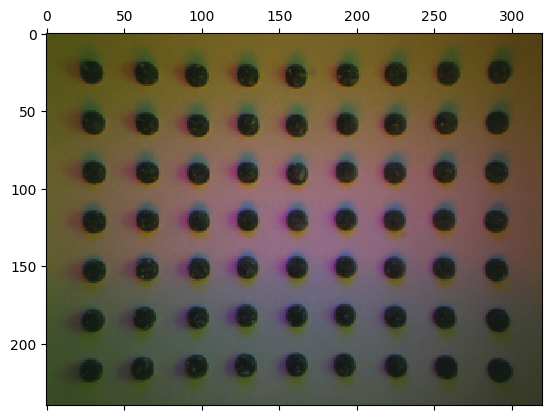

In [11]:
roi = (0,0,320,240)

img = cam.get_image(roi)
cam.save_image("test.jpg")

plt.matshow(img)

In [3]:
from gelsight import gsdevice as gs

In [5]:
cam = gs.Camera(gs.Finger.MINI, 0)
cam.connect()
res = (0, 0, 320, 240)

[tcp @ 0x2ee4680] Connection to tcp://localhost:8080 failed: Connection refused
[ERROR:0@274.965] global /io/opencv/modules/videoio/src/cap.cpp (164) open VIDEOIO(CV_IMAGES): raised OpenCV exception:

OpenCV(4.6.0) /io/opencv/modules/videoio/src/cap_images.cpp:253: error: (-5:Bad argument) CAP_IMAGES: can't find starting number (in the name of file): http://localhost:8080/?action=stream in function 'icvExtractPattern'




ERROR! reading image from camera


TypeError: Image data of dtype object cannot be converted to float

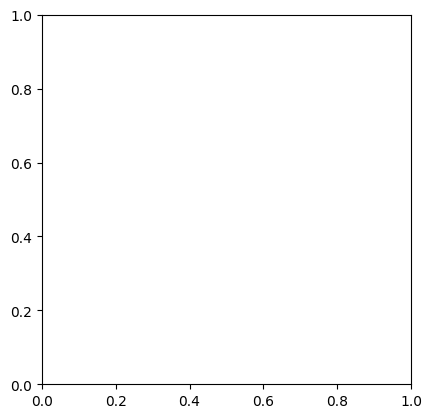

In [6]:
import matplotlib.pyplot as plt
plt.imshow(cam.get_raw_image())

In [8]:
forces = np.loadtxt("../tmp/time_force.txt")

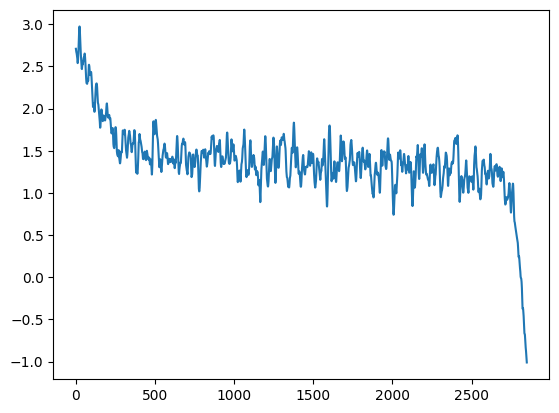

In [9]:
plt.plot(forces[:,1])

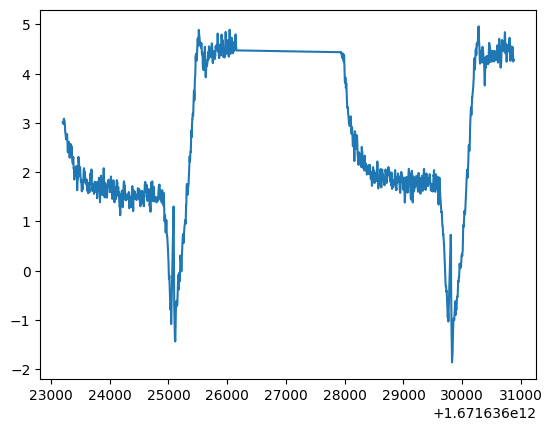

In [5]:
forces = np.load("../data/forces/01306f13-f016-4c21-8b0d-9cb927c5dab7.npy")
angles = np.load("../data/angles/01306f13-f016-4c21-8b0d-9cb927c5dab7.npy")

poses = np.zeros((angles.shape[0], 4))

for i in range(angles.shape[0]):
    matrix = np.array(Kinematics.forward(angles[i,1:])).reshape((4,4))
    poses[i,1:] = matrix[[0,1,2],3]

poses[:,0] = angles[:,0]


#plt.plot(poses[:,0], poses[:, 3])
plt.plot(forces[:,0],forces[:,1])


In [3]:
Kinematics.forward([0.3742012436992107, 0.3965798386015373, -0.027704081975832653, -2.373704329876077, 0.028091501702229765, 2.7978853032960225, 1.097400190761943])

[0.010583337239122546,
 -0.9999113386648716,
 -0.008081323054258627,
 0.0,
 0.9995900645105845,
 0.010364237836123417,
 0.026688677483194402,
 0.0,
 -0.026602554475250943,
 -0.008360465507408031,
 0.9996111277451302,
 0.0,
 0.4759696734247175,
 0.1696474454499246,
 0.16026538724498457,
 1.0]

In [4]:
Affine(Kinematics.forward([0.3742012436992107, 0.3965798386015373, -0.027704081975832653, -2.373704329876077, 0.028091501702229765, 2.7978853032960225, 1.097400190761943]))

[0.475970, 0.169647, 0.160265, -1.560212, 0.008081, 0.026693]

In [5]:
import numpy as np
import matplotlib.pyplot as plt

[[14. 15. 14. ... 25. 25. 23.]
 [11. 14. 15. ... 28. 27. 27.]
 [15. 15. 14. ... 30. 20. 20.]
 ...
 [20. 12. 17. ... 21. 20. 20.]
 [16. 18. 17. ... 21. 20. 19.]
 [14. 19. 19. ... 20. 19. 20.]]


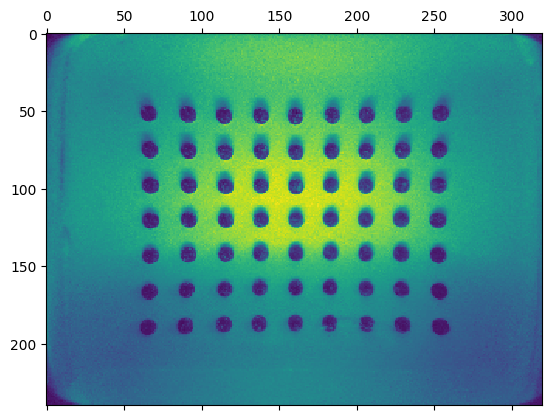

In [10]:
frames = np.load("../data/frames/0bd73f2c-cd6c-48f6-98a6-06b31f305d66_frames.npy")

plt.matshow(frames[15,:,:,0])

print(frames[15,:,:,0])

In [12]:
times  = np.load("../data/frames/0bd73f2c-cd6c-48f6-98a6-06b31f305d66_times.npy")
print(times.shape)

(74, 240, 320, 3)
